# Benchmark de los modelos base

Comparación de MobileNetV2, ResNet-50 y VGG-16 con las funciones de `src/benchmark.py` y
`src/stats.py`. Las observaciones pareadas son las corridas con la misma semilla y el mismo pliegue
de validación; para cada par (a, b), en el orden de `benchmark.models`, la diferencia es d = a - b.
Las comparaciones por pares usan las corridas que tienen los dos modelos del par, y las conjuntas,
las que tienen todos. Todos los parámetros (métrica primaria, partición, δ, α, potencia, bootstrap
y corrección por comparaciones múltiples) se leen de la sección `benchmark` de `configs/base.yaml`.
Si faltan corridas, cada sección muestra un aviso y el notebook continúa.

## 1. Configuración

Carga de la configuración y formato de las tablas: los números se muestran con seis cifras
significativas, de modo que los p-valores pequeños aparecen en notación científica en lugar de
redondearse a cero.

In [1]:
import pandas as pd

from src import benchmark, data, final
from src.report import configure_display, show

configure_display()
cfg = data.load_config()
cfg_b = cfg["benchmark"]
pd.Series({
    "modelos": ", ".join(cfg_b["models"]),
    "métrica primaria": cfg_b["primary_metric"],
    "partición de las pruebas": cfg_b["split"],
    "δ (margen de relevancia)": cfg_b["delta"],
    "α": cfg_b["alpha"],
    "potencia": cfg_b["power"],
    "ajuste de p-valores": cfg_b["p_adjust"],
    "bootstrap": f"{cfg_b['bootstrap']['method']}, {cfg_b['bootstrap']['n_resamples']} remuestreos, "
                 f"semilla {cfg_b['bootstrap']['seed']}",
    "McNemar exacto si b + c <": cfg_b["mcnemar_exact_below"],
}, name="valor").to_frame()

,valor
modelos,"mobilenetv2, resnet50, vgg16"
métrica primaria,balanced_accuracy
partición de las pruebas,test
δ (margen de relevancia),0.02
α,0.05
potencia,0.8
ajuste de p-valores,holm
bootstrap,"percentile, 10000 remuestreos, semilla 2026"
McNemar exacto si b + c <,25


Corridas de la ejecución definitiva (`final.label`) de cada modelo: previstas, terminadas y
pareadas con todos los modelos.

In [2]:
definitivas = benchmark.load_runs(cfg, final.final_label(cfg))
benchmark.availability_table(definitivas)

,previstas,terminadas,pareadas_con_todos
modelo (final),,,
mobilenetv2,5,5,5
resnet50,5,5,5
vgg16,5,5,5


## 2. Diferencia mínima detectable a posteriori

Sin estudio piloto (desviaciones D2 y D3, capítulo 7, «Número de corridas»): con las corridas
definitivas pareadas, por par de modelos, $\hat{\sigma}_d$ (ddof = 1) de las diferencias de la métrica
primaria en `benchmark.split`, $\delta / \hat{\sigma}_d$ y la diferencia mínima detectable
$\left(t_{1-\alpha/2,\,R-1} + t_{1-\beta,\,R-1}\right) \hat{\sigma}_d \sqrt{1/R + n_{\mathrm{val}}/n_{\mathrm{train}}}$.
Si supera $\delta$, la ausencia de significancia se interpreta como un resultado no concluyente.

In [3]:
dmd_posteriori = benchmark.posterior_mdd_table(definitivas, cfg)
dmd_posteriori

corridas_pareadas    media_d   sigma_d  \
modelo_a    modelo_b                                           
mobilenetv2 resnet50                  5 -0.0117933 0.0118727   
            vgg16                     5 -0.0106771  0.048094   
resnet50    vgg16                     5 0.00111625  0.051506   

                      delta_sobre_sigma_d  dif_minima_detectable  supera_delta  
modelo_a    modelo_b                                                            
mobilenetv2 resnet50              1.68453              0.0296072          True  
            vgg16                0.415852               0.119933          True  
resnet50    vgg16                0.388304               0.128441          True

## 3. Tabla comparativa

Por modelo, sobre `benchmark.split`: cada métrica como media ± desviación estándar entre corridas,
tiempo de entrenamiento por corrida, tiempo de inferencia por imagen en test y parámetros
entrenables (fase B).

In [4]:
benchmark.comparison_table(definitivas, cfg)

metrica,corridas,balanced_accuracy,accuracy,f1_macro,f1_weighted,auc_roc_macro_ovr,auc_pr_macro,mcc,ece,entrenamiento (h),inferencia (ms/imagen),parámetros entrenables,micro-lote x acumulación
modelo,,,,,,,,,,,,,
mobilenetv2,5,0.6316 ± 0.0160,0.6904 ± 0.0847,0.5474 ± 0.0463,0.7139 ± 0.0718,0.9194 ± 0.0194,0.6238 ± 0.0362,0.5141 ± 0.0635,0.1452 ± 0.0486,0.11 ± 0.02,2.98,2 232 839,32 x 1
resnet50,5,0.6434 ± 0.0155,0.6994 ± 0.0211,0.5833 ± 0.0227,0.7301 ± 0.0174,0.9330 ± 0.0075,0.6540 ± 0.0223,0.5432 ± 0.0093,0.1023 ± 0.0321,0.20 ± 0.05,3.19,23 548 935,32 x 1
vgg16,5,0.6423 ± 0.0377,0.7099 ± 0.0451,0.5780 ± 0.0571,0.7337 ± 0.0363,0.9125 ± 0.0124,0.6169 ± 0.0479,0.5272 ± 0.0568,0.0443 ± 0.0054,0.23 ± 0.05,2.63,134 289 223,32 x 1


Intervalos de confianza al 95 % de la media de cada métrica: por t de Student (`ic_t_*`) y por
bootstrap (`ic_boot_*`, con el método indicado en `metodo_boot`).

In [5]:
benchmark.metric_intervals(definitivas, cfg)

corridas     media        std  ic_t_bajo  \
modelo      metrica                                                       
mobilenetv2 balanced_accuracy         5  0.631601  0.0160239   0.611704   
            accuracy                  5  0.690426  0.0847221    0.58523   
            f1_macro                  5  0.547445  0.0463111   0.489943   
            f1_weighted               5  0.713919  0.0718126   0.624752   
            auc_roc_macro_ovr         5  0.919409  0.0194359   0.895276   
            auc_pr_macro              5   0.62376   0.036196   0.578817   
            mcc                       5  0.514075   0.063513   0.435213   
            ece                       5  0.145187  0.0485807  0.0848665   
resnet50    balanced_accuracy         5  0.643394  0.0155099   0.624136   
            accuracy                  5  0.699371  0.0210539   0.673229   
            f1_macro                  5  0.583265  0.0227493   0.555019   
            f1_weighted               5  0.730116  0.0174071   0.708503   
            auc_roc_macro_ovr         5  0.933041 0.00750718   0.923719   
            auc_pr_macro              5  0.653957  0.0222921   0.626278   
            mcc                       5  0.543162 0.00930445   0.531609   
            ece                       5  0.102307  0.0320573  0.0625027   
vgg16       balanced_accuracy         5  0.642278  0.0376531   0.595525   
            accuracy                  5  0.709853  0.0450894   0.653867   
            f1_macro                  5  0.577986  0.0571167   0.507066   
            f1_weighted               5  0.733733  0.0362792   0.688686   
            auc_roc_macro_ovr         5  0.912547  0.0124266   0.897118   
            auc_pr_macro              5  0.616887  0.0478963   0.557416   
            mcc                       5  0.527227  0.0568399   0.456651   
            ece                       5 0.0443114 0.00538725  0.0376222   

                               ic_t_alto  ic_boot_bajo  ic_boot_alto  \
modelo      metrica                                                    
mobilenetv2 balanced_accuracy   0.651497       0.62204      0.645927   
            accuracy            0.795623      0.614116      0.744934   
            f1_macro            0.604948      0.505719      0.574393   
            f1_weighted         0.803086      0.648429      0.757851   
            auc_roc_macro_ovr   0.943542      0.902979      0.933656   
            auc_pr_macro        0.668703      0.595887      0.650456   
            mcc                 0.592937      0.457426      0.556672   
            ece                 0.205508      0.114111      0.188537   
resnet50    balanced_accuracy   0.662652      0.631234      0.655554   
            accuracy            0.725513       0.68246      0.715444   
            f1_macro            0.611512      0.566554      0.601962   
            f1_weighted          0.75173      0.715741      0.743143   
            auc_roc_macro_ovr   0.942362      0.926524      0.938492   
            auc_pr_macro        0.681637      0.638137      0.673036   
            mcc                 0.554715      0.535828      0.550497   
            ece                 0.142112     0.0791363      0.130503   
vgg16       balanced_accuracy    0.68903      0.612303      0.671132   
            accuracy            0.765839      0.672676      0.740881   
            f1_macro            0.648905      0.534346      0.621523   
            f1_weighted         0.778779      0.702539      0.759353   
            auc_roc_macro_ovr   0.927977      0.902899      0.922196   
            auc_pr_macro        0.676359      0.579343      0.654432   
            mcc                 0.597803      0.483144      0.570923   
            ece                0.0510006     0.0403925     0.0489324   

                                                            metodo_boot  
modelo      metrica                                                      
mobilenetv2 balanced_accuracy  bootstrap percentile (10000 

Los intervalos anteriores reflejan la variabilidad entre corridas, pero no la de la muestra de
prueba, que es la misma en todas. Intervalo de confianza del 95 % por bootstrap sobre el conjunto
de prueba remuestreando lesiones (`lesion_id`), de modo que las imágenes de una misma lesión entran
o salen juntas: en cada remuestreo se recalcula la exactitud balanceada de cada corrida definitiva
y se promedia entre corridas. Se muestra para la media de cada modelo y para la diferencia entre
cada par (a - b, con los mismos remuestreos para todos los modelos). Remuestreos y semilla en
`benchmark.lesion_bootstrap`.

In [6]:
show(benchmark.lesion_bootstrap(definitivas, cfg))

**Exactitud balanceada media por modelo**

,corridas,media,ic_bajo,ic_alto,ee_bootstrap,lesiones,imagenes,metodo
modelo,,,,,,,,
mobilenetv2,5,0.631601,0.581433,0.684401,0.026035,1067,1431,bootstrap percentil por lesion_id (10000 remue...
resnet50,5,0.643394,0.589618,0.702339,0.0287495,1067,1431,bootstrap percentil por lesion_id (10000 remue...
vgg16,5,0.642278,0.587678,0.70078,0.0291366,1067,1431,bootstrap percentil por lesion_id (10000 remue...


**Diferencias entre pares (a - b)**

corridas_pareadas  diferencia    ic_bajo   ic_alto  \
modelo_a    modelo_b                                                       
mobilenetv2 resnet50                  5  -0.0117933 -0.0447314 0.0210145   
            vgg16                     5  -0.0106771 -0.0475589 0.0207514   
resnet50    vgg16                     5  0.00111625 -0.0288602 0.0303974   

                      ee_bootstrap  \
modelo_a    modelo_b                 
mobilenetv2 resnet50     0.0168866   
            vgg16         0.017322   
resnet50    vgg16         0.014918   

                                                                 metodo  
modelo_a    modelo_b                                                     
mobilenetv2 resnet50  bootstrap percentil por lesion_id (10000 remue...  
            vgg16     bootstrap percentil por lesion_id (10000 remue...  
resnet50    vgg16     bootstrap percentil por lesion_id (10000 remue...

La misma tabla comparativa sobre validación.

In [7]:
benchmark.comparison_table(definitivas, cfg, split="val")

metrica,corridas,balanced_accuracy,accuracy,f1_macro,f1_weighted,auc_roc_macro_ovr,auc_pr_macro,mcc,ece,entrenamiento (h),inferencia (ms/imagen),parámetros entrenables,micro-lote x acumulación
modelo,,,,,,,,,,,,,
mobilenetv2,5,0.7055 ± 0.0429,0.7024 ± 0.0730,0.5875 ± 0.0411,0.7247 ± 0.0648,0.9374 ± 0.0108,0.7089 ± 0.0273,0.5380 ± 0.0518,0.1351 ± 0.0436,0.11 ± 0.02,2.98,2 232 839,32 x 1
resnet50,5,0.7319 ± 0.0219,0.7068 ± 0.0267,0.6336 ± 0.0256,0.7351 ± 0.0219,0.9517 ± 0.0032,0.7380 ± 0.0149,0.5608 ± 0.0226,0.0930 ± 0.0379,0.20 ± 0.05,3.19,23 548 935,32 x 1
vgg16,5,0.6930 ± 0.0475,0.7038 ± 0.0510,0.5868 ± 0.0656,0.7290 ± 0.0417,0.9298 ± 0.0190,0.6639 ± 0.0769,0.5245 ± 0.0632,0.0504 ± 0.0038,0.23 ± 0.05,2.63,134 289 223,32 x 1


Costo computacional por modelo: media y desviación estándar del tiempo de entrenamiento y de la
inferencia por imagen, y parámetros.

In [8]:
benchmark.cost_summary(definitivas)

,entrenamiento_h_media,entrenamiento_h_std,inferencia_ms_imagen_media,inferencia_ms_imagen_std,parametros_entrenables,parametros_totales,micro_lote,pasos_de_acumulacion
model,,,,,,,,
mobilenetv2,0.114242,0.0184314,2.97805,1.83506,2232839,2266951,32,1
resnet50,0.195632,0.0535102,3.18574,0.956593,23548935,23602055,32,1
vgg16,0.230724,0.0514812,2.63432,1.80602,134289223,134289223,32,1


## 4. Ranking y trade-offs

Modelos ordenados por la media de la exactitud balanceada, con su rango medio entre las corridas
pareadas con todos los modelos (k = mejor).

In [9]:
benchmark.ranking_table(definitivas, cfg)

,posicion,corridas,media,std,rango_medio
balanced_accuracy (test),,,,,
resnet50,1,5,0.643394,0.0155099,2.2
vgg16,2,5,0.642278,0.0376531,2.2
mobilenetv2,3,5,0.631601,0.0160239,1.6


Exactitud balanceada (media ± desviación estándar) frente a los parámetros entrenables (escala
logarítmica) y frente al tiempo de entrenamiento por corrida.

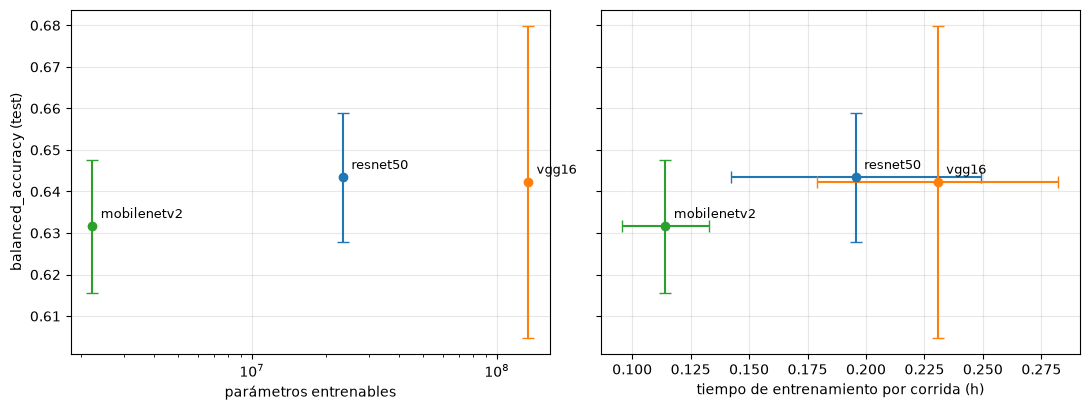

In [10]:
show(benchmark.plot_tradeoffs(definitivas, cfg))

## 5. Baseline y margen

### 5.1 Mejor modelo

Mejor y peor modelo por la media de la métrica primaria, con su desviación estándar e IC 95 % por
t de Student y por bootstrap.

In [11]:
benchmark.best_model_table(definitivas, cfg)

,modelo,corridas,media,std,ic_t_bajo,ic_t_alto,ic_boot_bajo,ic_boot_alto
mejor,resnet50,5,0.643394,0.0155099,0.624136,0.662652,0.631234,0.655554
peor,mobilenetv2,5,0.631601,0.0160239,0.611704,0.651497,0.62204,0.645927


### 5.2 Diferencias entre modelos

Diferencias absolutas y relativas (porcentaje respecto de la media pareada del segundo modelo), con
d de Cohen pareada y r de rango biserial: entre todos los pares, del mejor modelo frente a cada uno
de los demás y de cada uno de los demás frente al peor.

In [12]:
show({"Todos los pares": benchmark.pairwise_differences(definitivas, cfg),
      "Mejor modelo - otro": benchmark.pairwise_differences(definitivas, cfg, reference="mejor"),
      "Otro - peor modelo": benchmark.pairwise_differences(definitivas, cfg, reference="peor")})

**Todos los pares**

corridas_pareadas  diferencia  diferencia_relativa_pct  \
modelo_a    modelo_b                                                           
mobilenetv2 resnet50                  5  -0.0117933                 -1.83299   
            vgg16                     5  -0.0106771                 -1.66238   
resnet50    vgg16                     5  0.00111625                 0.173795   

                      d_cohen_pareada  r_rango_biserial  
modelo_a    modelo_b                                     
mobilenetv2 resnet50        -0.993314         -0.866667  
            vgg16           -0.222005         -0.333333  
resnet50    vgg16           0.0216722               0.2

**Mejor modelo - otro**

corridas_pareadas  diferencia  diferencia_relativa_pct  \
modelo_a modelo_b                                                              
resnet50 vgg16                        5  0.00111625                 0.173795   
         mobilenetv2                  5   0.0117933                  1.86721   

                      d_cohen_pareada  r_rango_biserial  
modelo_a modelo_b                                        
resnet50 vgg16              0.0216722               0.2  
         mobilenetv2         0.993314          0.866667

**Otro - peor modelo**

,,corridas_pareadas,diferencia,diferencia_relativa_pct,d_cohen_pareada,r_rango_biserial
modelo_a,modelo_b,,,,,
resnet50,mobilenetv2,5,0.0117933,1.86721,0.993314,0.866667
vgg16,mobilenetv2,5,0.0106771,1.69048,0.222005,0.333333


### 5.3 Mejora mínima detectable

Respecto del mejor modelo, con las corridas pareadas disponibles: $\hat{\sigma}_d$, diferencia
mínima detectable, potencia de la t pareada para detectar δ y corridas necesarias para δ.

In [13]:
benchmark.minimum_detectable_vs_best(definitivas, cfg)

corridas_pareadas   sigma_d  dif_minima_detectable  \
modelo_a modelo_b                                                          
resnet50 vgg16                        5  0.051506              0.0645322   
         mobilenetv2                  5 0.0118727              0.0148754   

                      potencia_para_delta  R_para_delta  
modelo_a modelo_b                                        
resnet50 vgg16                   0.104308       52.0551  
         mobilenetv2             0.801109       2.76597

### 5.4 Cotas de referencia

Cotas de `benchmark.reference_bounds` de `base.yaml`, con su valor, métrica, nota y fuente (clave de
`references.bib`). La diferencia entre la media del mejor modelo y la cota solo se calcula para las
cotas medidas con la métrica primaria; las demás quedan vacías porque usan otra métrica.

In [14]:
benchmark.reference_bounds_table(definitivas, cfg)

,valor,metrica,nota,fuente,mejor_modelo_menos_cota
cota,,,,,
Lectores con más de diez años de experiencia,0.627,exactitud en lotes de 30 imágenes,otra muestra de prueba y otra métrica; solo re...,tschandl2019,NaN
Tres mejores algoritmos del reto ISIC 2018 (mismo estudio),0.847,exactitud en lotes de 30 imágenes,otra muestra de prueba y otra métrica; solo re...,tschandl2019,NaN
Partición agrupada por lesión,0.7,exactitud balanceada,otra muestra de prueba; valor aproximado,pinar2026,-0.056606


## 6. Pruebas de hipótesis

Todas las pruebas usan la métrica primaria sobre `benchmark.split`, con α de `base.yaml`, y
reportan p-valores exactos.

### 6.1 Supuestos

Shapiro-Wilk de las diferencias pareadas de cada par.

In [15]:
normalidad = benchmark.normality_table(definitivas, cfg)
normalidad

corridas_pareadas  shapiro_W  shapiro_p  \
modelo_a    modelo_b                                            
mobilenetv2 resnet50                  5   0.898325   0.400695   
            vgg16                     5   0.843475    0.17476   
resnet50    vgg16                     5   0.834113   0.149295   

                      rechaza_normalidad  
modelo_a    modelo_b                      
mobilenetv2 resnet50               False  
            vgg16                  False  
resnet50    vgg16                  False

Gráficos Q-Q normales de las diferencias pareadas.

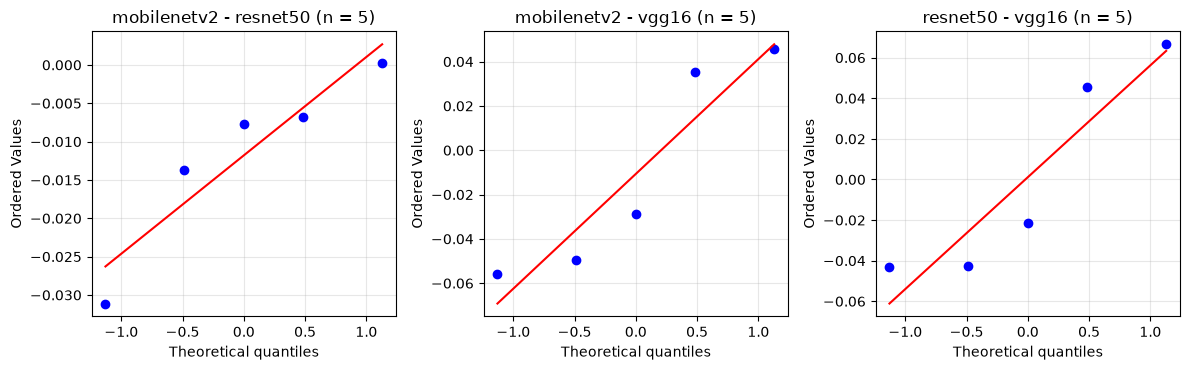

In [16]:
show(benchmark.plot_qq(definitivas, cfg))

Criterio automático: paramétrico si Shapiro-Wilk no rechaza la normalidad en ningún par; no
paramétrico en otro caso. El criterio determina la prueba principal de 6.2 y 6.3; las dos familias
se reportan siempre.

In [17]:
benchmark.criterion_table(normalidad)

,valor
criterio,paramétrico
comparación conjunta,ANOVA de medidas repetidas
comparaciones pareadas,t pareada
regla,paramétrico si Shapiro-Wilk no rechaza la norm...


### 6.2 Comparación conjunta

ANOVA de medidas repetidas (corridas como sujetos, con la corrección de Greenhouse-Geisser y eta
cuadrado parcial) y Friedman (con W de Kendall), sobre las corridas con todos los modelos.

In [18]:
benchmark.joint_tests(definitivas, cfg)

,estadistico,gl,p,p_greenhouse_geisser,efecto,medida_efecto,corridas
ANOVA de medidas repetidas,0.249007,"2, 8",0.785399,0.659511,0.0586036,eta² parcial,5
Friedman,1.2,2,0.548812,NaN,0.12,W de Kendall,5


Post-hoc de Nemenyi a partir de los rangos medios por corrida.

In [19]:
benchmark.nemenyi_table(definitivas, cfg)

rango_a  rango_b        q        p
modelo_a    modelo_b                                    
mobilenetv2 resnet50      1.6      2.2 0.948683 0.609411
            vgg16         1.6      2.2 0.948683 0.609411
resnet50    vgg16         2.2      2.2        0        1

Comparaciones pareadas con p-valores sin ajustar y ajustados por Holm (t pareada y Wilcoxon), y la
prueba principal según el criterio de 6.1.

In [20]:
pareadas = benchmark.pairwise_tests(definitivas, cfg)
benchmark.pairwise_adjusted_table(pareadas)

corridas_pareadas  diferencia_media       p_t  p_t_holm  \
modelo_a    modelo_b                                                            
mobilenetv2 resnet50                  5        -0.0117933 0.0904997  0.271499   
            vgg16                     5        -0.0106771  0.645642         1   
resnet50    vgg16                     5        0.00111625  0.963672         1   

                      p_wilcoxon  p_wilcoxon_holm prueba_principal  \
modelo_a    modelo_b                                                 
mobilenetv2 resnet50       0.125            0.375        t pareada   
            vgg16          0.625                1        t pareada   
resnet50    vgg16         0.8125                1        t pareada   

                      significativa  
modelo_a    modelo_b                 
mobilenetv2 resnet50          False  
            vgg16             False  
resnet50    vgg16             False

### 6.3 Comparaciones pareadas

Por par: diferencia media con IC 95 % por bootstrap, t pareada y Wilcoxon exacto (distribución de
permutación exacta, válida también con empates) con p-valores sin ajustar y ajustados, d de Cohen
pareada, delta de Cliff, probabilidad de superioridad pareada, potencia de la t pareada para δ y
diferencia mínima detectable.

In [21]:
pareadas

corridas_pareadas  diferencia_media  ic_boot_bajo  \
modelo_a    modelo_b                                                      
mobilenetv2 resnet50                  5        -0.0117933    -0.0217375   
            vgg16                     5        -0.0106771    -0.0481138   
resnet50    vgg16                     5        0.00111625    -0.0384107   

                      ic_boot_alto         t  gl       p_t  p_t_holm  W_mas  \
modelo_a    modelo_b                                                          
mobilenetv2 resnet50   -0.00395604  -2.22112   4 0.0904997  0.271499      1   
            vgg16        0.0267596 -0.496417   4  0.645642         1      5   
resnet50    vgg16        0.0406432 0.0484606   4  0.963672         1      9   

                      p_wilcoxon  p_wilcoxon_holm  empates_wilcoxon  \
modelo_a    modelo_b                                                  
mobilenetv2 resnet50       0.125            0.375             False   
            vgg16          0.625                1             False   
resnet50    vgg16         0.8125                1             False   

                      d_cohen_pareada  delta_cliff  prob_superioridad  \
modelo_a    modelo_b                                                    
mobilenetv2 resnet50        -0.993314        -0.52                0.2   
            vgg16           -0.222005        -0.12                0.4   
resnet50    vgg16           0.0216722        -0.04                0.4   

                      potencia_para_delta  dif_minima_detectable  \
modelo_a    modelo_b                                               
mobilenetv2 resnet50             0.801109              0.0148754   
            vgg16                0.112375              0.0602573   
resnet50    vgg16                0.104308              0.0645322   

                     prueba_principal  significativa  
modelo_a    modelo_b                                  
mobilenetv2 resnet50        t pareada          False  
            vgg16           t pareada          False  
resnet50    vgg16           t pareada          False

### 6.4 Validación cruzada repetida (Nadeau y Bengio)

t con la varianza corregida $(1/n + n_\text{val}/n_\text{train})\, s^2$, que tiene en cuenta el
solapamiento de los conjuntos de entrenamiento entre corridas, con la razón media entre el tamaño de
validación y el de entrenamiento, en las particiones de `benchmark.nadeau_bengio_splits`.

In [22]:
benchmark.nadeau_bengio_table(definitivas, cfg)

diferencia_media  n         t  gl        p  \
particion modelo_a    modelo_b                                               
val       mobilenetv2 resnet50        -0.0263097  5   -1.2928   4 0.265699   
                      vgg16            0.0125197  5   1.01934   4 0.365679   
          resnet50    vgg16            0.0388294  5   1.50376   4 0.207078   
test      mobilenetv2 resnet50        -0.0117933  5  -1.48074   4 0.212787   
                      vgg16           -0.0106771  5 -0.330945   4 0.757297   
          resnet50    vgg16           0.00111625  5 0.0323071   4 0.975775   

                                ee_corregido  ee_sin_corregir   p_holm  \
particion modelo_a    modelo_b                                           
val       mobilenetv2 resnet50     0.0203509        0.0135673 0.621234   
                      vgg16        0.0122822       0.00818817 0.621234   
          resnet50    vgg16        0.0258215        0.0172144 0.621234   
test      mobilenetv2 resnet50    0.00796446       0.00530964 0.638361   
                      vgg16        0.0322624        0.0215083        1   
          resnet50    vgg16        0.0345513        0.0230342        1   

                                razon_val_train  
particion modelo_a    modelo_b                   
val       mobilenetv2 resnet50             0.25  
                      vgg16                0.25  
          resnet50    vgg16                0.25  
test      mobilenetv2 resnet50             0.25  
                      vgg16                0.25  
          resnet50    vgg16                0.25

### 6.5 Equivalencia (TOST)

Dos pruebas t unilaterales pareadas con margen (-δ, δ) para cada par, e IC al 1 - 2α de la
diferencia. Los modelos son equivalentes si `p_tost` < α.

In [23]:
benchmark.tost_table(definitivas, cfg)

diferencia_media  n  p_inferior  p_superior    p_tost  \
modelo_a    modelo_b                                                          
mobilenetv2 resnet50        -0.0117933  5   0.0985458  0.00195574 0.0985458   
            vgg16           -0.0106771  5    0.343517    0.113468  0.343517   
resnet50    vgg16           0.00111625  5    0.205576     0.22918   0.22918   

                        ic_bajo      ic_alto  equivalentes  
modelo_a    modelo_b                                        
mobilenetv2 resnet50 -0.0231127 -0.000473995         False  
            vgg16    -0.0565295    0.0351753         False  
resnet50    vgg16    -0.0479891    0.0502216         False

### 6.6 McNemar

McNemar sobre los aciertos por imagen de test de cada par en cada corrida pareada: binomial exacta
si las discordancias b + c son menos de `mcnemar_exact_below`, chi-cuadrado con corrección de
continuidad si no, y p ajustado por Holm entre los pares de cada corrida. Resumen entre corridas.

In [24]:
mcnemar = benchmark.mcnemar_by_run(definitivas, cfg)
benchmark.mcnemar_summary(mcnemar, cfg)

corridas  b_medio  c_medio  corridas_significativas  \
modelo_a    modelo_b                                                        
mobilenetv2 resnet50         5    184.2      197                        5   
            vgg16            5    171.4    199.2                        4   
resnet50    vgg16            5    144.4    159.4                        4   

                      mediana_p_holm  min_p_holm  max_p_holm  
modelo_a    modelo_b                                          
mobilenetv2 resnet50     1.36513e-05 8.30399e-32   0.0328383  
            vgg16        3.51174e-05 1.14243e-43   0.0669046  
resnet50    vgg16         0.00410156 9.63011e-10   0.0808733

Resultados por corrida.

In [25]:
mcnemar

b    c  estadistico           p  \
run   modelo_a    modelo_b                                      
s0_f0 mobilenetv2 resnet50  210  125      21.0627   4.445e-06   
                  vgg16     202  153      6.49014   0.0108474   
      resnet50    vgg16     183  219      3.04726   0.0808733   
s0_f1 mobilenetv2 resnet50  181  225      4.55419   0.0328383   
                  vgg16     153  241      19.2107 1.17058e-05   
      resnet50    vgg16     115  159      6.74818  0.00938436   
s0_f2 mobilenetv2 resnet50   94  341      139.117   4.152e-32   
                  vgg16      72  364      194.222 3.80809e-44   
      resnet50    vgg16      95  140       8.2383  0.00410156   
s0_f3 mobilenetv2 resnet50  193  143      7.14583  0.00751384   
                  vgg16     261  102      68.7713 1.10567e-16   
      resnet50    vgg16     205   96      38.7508 4.81505e-10   
s0_f4 mobilenetv2 resnet50  243  151      21.0178 4.55044e-06   
                  vgg16     169  136      3.35738   0.0669046   
      resnet50    vgg16     124  183      10.9577 0.000932177   

                                                                metodo  \
run   modelo_a    modelo_b                                               
s0_f0 mobilenetv2 resnet50  chi-cuadrado con corrección de continuidad   
                  vgg16     chi-cuadrado con corrección de continuidad   
      resnet50    vgg16     chi-cuadrado con corrección de continuidad   
s0_f1 mobilenetv2 resnet50  chi-cuadrado con corrección de continuidad   
                  vgg16     chi-cuadrado con corrección de continuidad   
      resnet50    vgg16     chi-cuadrado con corrección de continuidad   
s0_f2 mobilenetv2 resnet50  chi-cuadrado con corrección de continuidad   
                  vgg16     chi-cuadrado con corrección de continuidad   
      resnet50    vgg16     chi-cuadrado con corrección de continuidad   
s0_f3 mobilenetv2 resnet50  chi-cuadrado con corrección de continuidad   
                  vgg16     chi-cuadrado con corrección de continuidad   
      resnet50    vgg16     chi-cuadrado con corrección de continuidad   
s0_f4 mobilenetv2 resnet50  chi-cuadrado con corrección de continuidad   
                  vgg16     chi-cuadrado con corrección de continuidad   
      resnet50    vgg16     chi-cuadrado con corrección de continuidad   

                                p_holm  
run   modelo_a    modelo_b              
s0_f0 mobilenetv2 resnet50  1.3335e-05  
                  vgg16      0.0216949  
      resnet50    vgg16      0.0808733  
s0_f1 mobilenetv2 resnet50   0.0328383  
                  vgg16    3.51174e-05  
      resnet50    vgg16      0.0187687  
s0_f2 mobilenetv2 resnet50 8.30399e-32  
                  vgg16    1.14243e-43  
      resnet50    vgg16     0.00410156  
s0_f3 mobilenetv2 resnet50  0.00751384  
                  vgg16    3.31702e-16  
      resnet50    vgg16    9.63011e-10  
s0_f4 mobilenetv2 resnet50 1.36513e-05  
                  vgg16      0.0669046  
      resnet50    vgg16     0.00186435

### 6.7 DeLong y AUC macro

DeLong uno contra el resto por clase para cada par en cada corrida pareada (test), con p ajustado
por Holm por separado para cada par y corrida, sobre sus siete contrastes (uno por clase). Resumen
entre corridas por par y clase.

In [26]:
delong = benchmark.delong_by_run(definitivas, cfg)
benchmark.delong_summary(delong, cfg)

corridas  auc_a_media  auc_b_media  \
modelo_a    modelo_b clase                                       
mobilenetv2 resnet50 akiec         5     0.927418     0.943296   
                     bcc           5     0.963074     0.971513   
                     bkl           5     0.902336     0.909002   
                     df            5     0.887412     0.910958   
                     mel           5     0.852788      0.87952   
                     nv            5     0.919299     0.942935   
                     vasc          5     0.983536     0.974061   
            vgg16    akiec         5     0.927418     0.926473   
                     bcc           5     0.963074     0.968197   
                     bkl           5     0.902336     0.879962   
                     df            5     0.887412     0.909826   
                     mel           5     0.852788     0.840242   
                     nv            5     0.919299     0.928866   
                     vasc          5     0.983536     0.934238   
resnet50    vgg16    akiec         5     0.943296     0.926473   
                     bcc           5     0.971513     0.968197   
                     bkl           5     0.909002     0.879962   
                     df            5     0.910958     0.909826   
                     mel           5      0.87952     0.840242   
                     nv            5     0.942935     0.928866   
                     vasc          5     0.974061     0.934238   

                            diferencia_media  diferencia_std  \
modelo_a    modelo_b clase                                     
mobilenetv2 resnet50 akiec        -0.0158782      0.00635463   
                     bcc         -0.00843873       0.0101383   
                     bkl          -0.0066664       0.0237155   
                     df           -0.0235461       0.0626683   
                     mel          -0.0267325       0.0379836   
                     nv           -0.0236358       0.0219195   
                     vasc         0.00947555       0.0303368   
            vgg16    akiec       0.000944907       0.0162666   
                     bcc         -0.00512259       0.0173185   
                     bkl            0.022374       0.0626707   
                     df           -0.0224145       0.0573496   
                     mel            0.012546       0.0720308   
                     nv          -0.00956671       0.0337546   
                     vasc          0.0492984       0.0230425   
resnet50    vgg16    akiec         0.0168231       0.0198701   
                     bcc          0.00331614       0.0148503   
                     bkl           0.0290404       0.0480613   
                     df           0.00113154       0.0433033   
                     mel           0.0392785       0.0370477   
                     nv            0.0140691       0.0152488   
                     vasc          0.0398228       0.0288181   

                            corridas_significativas  mediana_p_holm  
modelo_a    modelo_b clase                                           
mobilenetv2 resnet50 akiec                        0               1  
                     bcc                          0               1  
                     bkl                          1               1  
                     df                           0        0.245515  
                     mel                          2               1  
                     nv                           4       0.0096445  
                     vasc                         0               1  
            vgg16    akiec                        0        0.958911  
                     bcc                          0         0.34503  
                     bkl                          3     0.000213507  
                     df                           1        0.387144  
                     mel                          3     7.32476e-05  
                     nv                           3     

Diferencia de AUC-ROC macro uno contra el resto por corrida pareada, con IC 95 % por bootstrap
percentil estratificado por clase (`bootstrap.n_resamples_auc` remuestreos), y resumen entre corridas.

In [27]:
auc_bootstrap = benchmark.auc_bootstrap_by_run(definitivas, cfg)
benchmark.auc_bootstrap_summary(auc_bootstrap)

corridas  diferencia_media  diferencia_std  \
modelo_a    modelo_b                                               
mobilenetv2 resnet50         5        -0.0136317       0.0214372   
            vgg16            5        0.00686563       0.0291516   
resnet50    vgg16            5         0.0204974       0.0133897   

                      corridas_ic_excluye_0  
modelo_a    modelo_b                         
mobilenetv2 resnet50                      3  
            vgg16                         3  
resnet50    vgg16                         4

In [28]:
auc_bootstrap

diferencia_auc_macro    ic_bajo     ic_alto  \
run   modelo_a    modelo_b                                                
s0_f0 mobilenetv2 resnet50             0.0187929 0.00268076   0.0370409   
                  vgg16                0.0382581  0.0259608   0.0537166   
      resnet50    vgg16                0.0194652 0.00549374   0.0326871   
s0_f1 mobilenetv2 resnet50            -0.0315703 -0.0456535  -0.0164289   
                  vgg16               -0.0104951 -0.0248717  0.00639368   
      resnet50    vgg16                0.0210752 0.00568099    0.038241   
s0_f2 mobilenetv2 resnet50             -0.034565 -0.0482943  -0.0204055   
                  vgg16               -0.0317042 -0.0546819 -0.00940317   
      resnet50    vgg16               0.00286078 -0.0191503   0.0252381   
s0_f3 mobilenetv2 resnet50           -0.00866494  -0.020201  0.00298728   
                  vgg16                0.0318562  0.0185546     0.04662   
      resnet50    vgg16                0.0405212  0.0297176   0.0529314   
s0_f4 mobilenetv2 resnet50            -0.0121514 -0.0261308 0.000501466   
                  vgg16               0.00641309 -0.0102738    0.023579   
      resnet50    vgg16                0.0185645 0.00510558   0.0360599   

                            p_bootstrap  remuestreos  
run   modelo_a    modelo_b                            
s0_f0 mobilenetv2 resnet50         0.01         1000  
                  vgg16               0         1000  
      resnet50    vgg16           0.012         1000  
s0_f1 mobilenetv2 resnet50            0         1000  
                  vgg16           0.186         1000  
      resnet50    vgg16           0.008         1000  
s0_f2 mobilenetv2 resnet50            0         1000  
                  vgg16           0.006         1000  
      resnet50    vgg16           0.888         1000  
s0_f3 mobilenetv2 resnet50         0.17         1000  
                  vgg16               0         1000  
      resnet50    vgg16               0         1000  
s0_f4 mobilenetv2 resnet50        0.064         1000  
                  vgg16           0.478         1000  
      resnet50    vgg16           0.004         1000

### 6.8 Descomposición de la varianza

Suma de cuadrados de la métrica primaria atribuible al modelo, a la corrida (separada en semilla,
pliegue y su interacción si las corridas forman un producto completo) y al residual (modelo x
corrida), con su proporción del total.

In [29]:
benchmark.variance_table(definitivas, cfg)

,SC,gl,proporcion,CM,F,p
fuente,,,,,,
modelo,0.000423882,2,0.0524333,0.000211941,0.249007,0.785399
corrida (semilla y pliegue),0.000851174,4,0.105289,0.000212794,0.250009,0.901754
residual (modelo x corrida),0.00680915,8,0.842278,0.000851143,NaN,NaN
total,0.0080842,14,1,0.000577443,NaN,NaN


## 7. Robustez comparada

Métricas de test por fuente (`dataset`) de los tres modelos en una misma tabla: media y desviación
estándar entre corridas.

In [30]:
benchmark.robustness_by_group(definitivas, cfg, "dataset")

/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pr

/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pr

mobilenetv2                                  \
               n_imagenes corridas balanced_accuracy_mean   
dataset                                                     
vidir_molemax         567        5               0.732038   
vidir_modern          455        5               0.561906   
rosendahl             330        5               0.516548   
vienna_dias            79        5                  0.545   

                                                                              \
              balanced_accuracy_std accuracy_mean accuracy_std f1_macro_mean   
dataset                                                                        
vidir_molemax             0.0570465      0.867372    0.0946352      0.540611   
vidir_modern              0.0145532      0.601758    0.0841991      0.513804   
rosendahl                 0.0327498      0.524242    0.0681313      0.482926   
vienna_dias                0.176083      0.625316     0.217338      0.464493   

                                            resnet50           \
              f1_macro_std pocas_imagenes n_imagenes corridas   
dataset                                                         
vidir_molemax     0.102264          False        567        5   
vidir_modern     0.0407692          False        455        5   
rosendahl        0.0522674          False        330        5   
vienna_dias       0.119486          False         79        5   

                                                                          \
              balanced_accuracy_mean balanced_accuracy_std accuracy_mean   
dataset                                                                    
vidir_molemax                0.76398             0.0446702       0.93157   
vidir_modern                0.561974              0.045516      0.568791   
rosendahl                    0.52295             0.0191829      0.512121   
vienna_dias                 0.457857              0.161711      0.567089   

                                                                      \
              accuracy_std f1_macro_mean f1_macro_std pocas_imagenes   
dataset                                                                
vidir_molemax    0.0411619      0.662341     0.057607          False   
vidir_modern     0.0359258      0.518312    0.0114176          False   
rosendahl        0.0311252      0.490734    0.0308425          False   
vienna_dias       0.107185       0.32962      0.13585          False   

                   vgg16                                  \
              n_imagenes corridas balanced_accuracy_mean   
dataset                                                    
vidir_molemax        567        5                0.69089   
vidir_modern         455        5               0.536221   
rosendahl            330        5               0.517629   
vienna_dias           79        5               0.688571   

                                                                              \
              balanced_accuracy_std accuracy_mean accuracy_std f1_macro_mean   
dataset                                                                        
vidir_molemax             0.0987489      0.940388     0.012558      0.596285   
vidir_modern              0.0564624      0.568352    0.0725042      0.501121   
rosendahl                 0.0420942      0.529091    0.0676104       0.49178   
vienna_dias                0.139912      0.625316     0.141693      0.616837   

                                           
              f1_macro_std pocas_imagenes  
dataset                                    
vidir_molemax     0.113519          False  
vidir_modern     0.0526149          False  
rosendahl        0.0635269          False  
vienna_dias       0.166281          False